### Libraries

In [ ]:
%%capture
!pip install tqdm pandas numpy scikit-learn nltk llm bertopic sentence-transformers cuml accelerate

In [ ]:
import os
from tqdm import tqdm
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer
import nltk
from nltk.corpus import stopwords

from sentence_transformers import SentenceTransformer
import torch
from bertopic import BERTopic
from bertopic.vectorizers import ClassTfidfTransformer
try:
    from cuml.manifold import UMAP
    from cuml.cluster import HDBSCAN
except ImportError:
    from umap import UMAP
    from hdbscan import HDBSCAN

# Speech Data

In [2]:
df = pd.read_parquet("clean_paragraphs.parquet")
df.head(10)

,Speech_ID,Paragraph_ID,TEXT_SPAN,role,language_of_text,name
0,81893,81893_p0,La commission propose de ne pas donner suite à...,President,FR,Bugnon André
1,81894,81894_p0,"Ich möchte Sie nur nochmals bitten, das Result...",For the committee,DE,Widmer Hans
2,81894,81894_p1,"In diesem Sinne bitte ich Sie nochmals, den An...",For the committee,DE,Widmer Hans
3,81895,81895_p0,Der Bundesrat beantragt die Annahme des Postul...,Member of the federal council,DE,Schmid Samuel
4,81895,81895_p1,Aber es geht hier noch um andere Fragen. Es ge...,Member of the federal council,DE,Schmid Samuel
5,81895,81895_p2,"Verschiedene andere Fragen, beispielsweise jen...",Member of the federal council,DE,Schmid Samuel
6,81895,81895_p3,"Also sind wir bereit, die Analysen zu machen, ...",Member of the federal council,DE,Schmid Samuel
7,81895,81895_p4,In diesem Sinne beantragt der Bundesrat die An...,Member of the federal council,DE,Schmid Samuel
8,81899,81899_p0,"Monsieur Burkhalter, qui était prévu comme rap...",President,FR,Bugnon André
9,83146,83146_p0,Erlauben Sie mir noch ein paar Bemerkungen.,For the committee,DE,Schwaller Urs


# Bills (SwissDomainBERT2)

In [3]:
topic_df = pd.read_parquet("240102_bills_swissdomainbert2_predictions.parquet")
topic_df.head(10)

,bill_number,text,date,chamber,domain_id,source,language,time_span_decade,time_span_25y,domain_id_prediction_swissdomainbert2,domain_logits_swissdomainbert2,domain_name_prediction_swissdomainbert2,embeddings_swissdomainbert2,umap_swissdomainbert2
0,...,"Motion der Kommissionsminderheit (Renschier, ....",1987-01-01,Unknown,NaN,graph,DE,1980.0,1975.0,3,"[1.4315958196675638e-07, 8.955157682066783e-05...",Civil Rights,"[-0.6744987368583679, -0.5489828586578369, -0....","[3.0162856578826904, 6.312497615814209]"
1,0.10335,"195. Freymond, vom 26. Juni 1969.Ein ausländis...",1969-06-26,Nationalrat,NaN,graph,DE,1960.0,1950.0,14,"[3.644416892711888e-06, 3.176500104018487e-05,...","Technology, Communication","[0.3503628969192505, -0.17170414328575134, -0....","[6.8938212394714355, 5.891744136810303]"
2,00.001,Der Europarat beging 1999 sein 50-jähriges Bes...,2000-01-12,Ständerat,NaN,graph,DE,2000.0,2000.0,13,"[2.939555633929558e-05, 4.6187258703866974e-05...",International Affairs,"[0.4193879961967468, -0.16224949061870575, 0.2...","[13.971299171447754, -0.31970149278640747]"
3,00.003,In seinem Postulat vom 6. Oktober 1976 beauftr...,2000-01-19,Ständerat,13.0,graph,DE,2000.0,2000.0,13,"[2.9378930776147172e-05, 3.518968151183799e-05...",International Affairs,"[0.42163193225860596, -0.15665242075920105, 0....","[13.986701011657715, -0.2620127201080322]"
4,00.006,Bericht des Bundesrates über seine Geschäftsfü...,2000-03-09,Nationalrat,NaN,graph,DE,2000.0,2000.0,15,"[7.351007297984324e-06, 5.184900146559812e-06,...",Government Operations,"[-0.26835861802101135, -0.4732978343963623, 0....","[-1.9103219509124756, -2.2852351665496826]"
5,00.007,Das Einleitungskapiteldes Berichts ist der Bed...,2000-01-12,Nationalrat,20.0,graph,DE,2000.0,2000.0,20,"[2.210132333857473e-05, 1.302836972172372e-05,...",Economy,"[-0.5453465580940247, -0.3741756081581116, 0.1...","[3.557896614074707, 2.900557279586792]"
6,00.008,Das Bundesgesetz vom 7. Oktober 1983 über den ...,2000-03-01,Ständerat,NaN,graph,DE,2000.0,2000.0,6,"[0.29752904176712036, 0.0001268720516236499, 0...","Education, Research","[-1.0216357707977295, 0.07308592647314072, -0....","[6.255590915679932, 3.2767133712768555]"
7,00.009,Mit dem Bundesbeschluss vom 17. Dezember 1998 ...,2000-01-26,Nationalrat,16.0,graph,DE,2000.0,2000.0,16,"[4.379471647553146e-05, 0.00014013775216881186...","Culture, Arts, Religion, Sport, Entertainment","[-1.3953583240509033, -0.15909360349178314, 0....","[-2.8011155128479004, 1.0940746068954468]"
8,00.010,Die Staatsrechnung 1999 präsentiert sich erneu...,2000-03-29,Nationalrat,19.0,graph,DE,2000.0,2000.0,19,"[0.00013363057223614305, 1.5576872101519257e-0...","Public Finances, Taxation","[-1.3426238298416138, -0.4670485258102417, 0.1...","[6.670615196228027, 10.868708610534668]"
9,00.011,Mit dem ersten Nachtrag zum Voranschlag 2000 e...,2000-03-29,Nationalrat,16.0,graph,DE,2000.0,2000.0,16,"[0.00501673761755228, 0.00025986498803831637, ...","Culture, Arts, Religion, Sport, Entertainment","[-1.2834326028823853, -0.5486190319061279, 0.0...","[-4.552356243133545, -6.336331367492676]"


# Embeddings (Qwen3-0.6B)

In [4]:
# Load the embedding model
EMBEDDING_MODEL = "Qwen/Qwen3-Embedding-0.6B"
embedder = SentenceTransformer(
    EMBEDDING_MODEL,
    trust_remote_code=True,
    model_kwargs={
        "torch_dtype": torch.bfloat16,
        "attn_implementation": "sdpa",
    },
    processor_kwargs={
        "padding_side": "left"
    },
)

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

In [5]:
#embeddings = embedder.encode(
#    texts,
#    normalize_embeddings=True,
#    batch_size=64,
#    show_progress_bar=True,
#)

In [6]:
#np.save(f"paragraph_embeddings_{EMBEDDING_MODEL.split("/")[-1]}.npy", embeddings)

In [7]:
# Load pre-computed embeddings
embeddings = np.load(f"paragraph_embeddings_{EMBEDDING_MODEL.split("/")[-1]}.npy")

# Normalize embeddings to unit length
embeddings = embeddings / np.linalg.norm(embeddings, axis=1, keepdims=True)
embeddings.shape

(303384, 1024)

In [8]:
texts = df["TEXT_SPAN"].tolist()
bills_topics = topic_df['domain_name_prediction_swissdomainbert2'].unique().tolist()
print(f"Found {len(bills_topics)} unique topics: {bills_topics}")

Found 21 unique topics: ['Civil Rights', 'Technology, Communication', 'International Affairs', 'Government Operations', 'Economy', 'Education, Research', 'Culture, Arts, Religion, Sport, Entertainment', 'Public Finances, Taxation', 'Agriculture', 'Social Welfare', 'Labor', 'Health', 'National Security, Armed Forces, Defense', 'Environment', 'Energy', '(Public) Transportation', 'Finances, Financial Sector', 'Spatial Planing, Civil Engineering', 'Migration', 'Parliamentary Procedure', 'Criminal Law']


# BERTopic Model (UMAP + HDBSCAN)

In [9]:
# Hyperparameters for BERTopic
RANDOM_SEED = 42

# UMAP
N_NEIGHBORS = 20
N_COMPONENTS = 5
METRIC = "cosine"

# HDBSCAN
MIN_CLUSTER_SIZE = 150
MIN_SAMPLES = 10
CLUSTER_SELECTION_METHOD = "leaf" # "eom" (excess of mass) or "leaf"
CLUSTER_SELECTION_EPSILON = 0.1

# Zero-Shot topic
ZEROSHOT_MIN_SIMILARITY = 0.65 # Min cos similarity between speech embedding and predefined topic embedding to assign the topic to the speech

In [10]:
# Download stopwords for German, French, and Italian
nltk.download("stopwords")

# Combine stopwords from German, French, and Italian
stop_words_multi = (
    stopwords.words("german")
    + stopwords.words("french")
    + stopwords.words("italian")
)

# UMAP for dimensionality reduction
umap_model = UMAP(
    n_neighbors=N_NEIGHBORS,
    n_components=N_COMPONENTS,
    metric=METRIC,
    random_state=RANDOM_SEED
)

# HDBSCAN for clustering
hdbscan_model = HDBSCAN(
    min_cluster_size=MIN_CLUSTER_SIZE,
    min_samples=MIN_SAMPLES,
    cluster_selection_method=CLUSTER_SELECTION_METHOD,
    cluster_selection_epsilon=CLUSTER_SELECTION_EPSILON,
    prediction_data=True
)

# CountVectorizer with custom stop words (German, French, Italian)
vectorizer_model = CountVectorizer(
    stop_words=stop_words_multi,
)
# TF-IDF transformer that reduces the importance of frequent words across topics
ctfidf_model = ClassTfidfTransformer(reduce_frequent_words=True)

# Initialize BERTopic with the specified models and parameters
topic_model = BERTopic(
    embedding_model=embedder,
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,
    vectorizer_model=vectorizer_model,
    ctfidf_model=ctfidf_model,
    verbose=True,
    zeroshot_topic_list=bills_topics,
    zeroshot_min_similarity=ZEROSHOT_MIN_SIMILARITY,
)

[nltk_data] Downloading package stopwords to /home/matteo/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [11]:
overwrite_model = False
if os.path.exists(f"bertopic_model_{len(texts)}_samples") and not overwrite_model:
    print("Model found, loading...")
    topic_model = BERTopic.load(
        f"bertopic_model_{len(texts)}_samples",
        embedding_model=embedder,
    )
else:
    print("No model found, fitting a new one...")
    topics, probs = topic_model.fit_transform(texts, embeddings=embeddings)

Model found, loading...


In [12]:
topic_model.get_topic_info()

,Topic,Count,Name,Representation,Representative_Docs
0,0,599,0_absolutes_absolue_scrutin_blancs,"[absolutes, absolue, scrutin, blancs, majorité...",NaN
1,1,20,1_technologie_0477_innovation_a2310,"[technologie, 0477, innovation, a2310, 760, kt...",NaN
2,2,23,2_affaires_étrangères_dae_département,"[affaires, étrangères, dae, département, préfe...",NaN
3,3,15,3_unités_administratives_budget_indicateurs,"[unités, administratives, budget, indicateurs,...",NaN
4,4,26,4_économie_économique_secrétariat_petit,"[économie, économique, secrétariat, petit, eta...",NaN
...,...,...,...,...,...
156,156,1125,156_einbürgerung_integration_niederlassungsbew...,"[einbürgerung, integration, niederlassungsbewi...",NaN
157,157,1384,157_bauzonen_bauten_ausserhalb_bauzone,"[bauzonen, bauten, ausserhalb, bauzone, raumpl...",NaN
158,158,432,158_zweitwohnungen_wohnungen_erstwohnungen_tou...,"[zweitwohnungen, wohnungen, erstwohnungen, tou...",NaN
159,159,1889,159_verkehr_güterverkehr_den_auch,"[verkehr, güterverkehr, den, auch, wir, das, i...",NaN


In [ ]:
new_topics = topic_model.reduce_outliers(texts, topics, strategy="embeddings", embeddings=embeddings)
topic_model.update_topics(texts, topics=new_topics)

In [ ]:
topic_model.get_topic_info()

In [ ]:
topic_model.visualize_topics()

In [ ]:
top_n = 20
topic_model.visualize_heatmap(top_n_topics=top_n, title=f"Top {top_n} Topics Heatmap")

In [ ]:
topics_per_class = topic_model.topics_per_class(texts, df["name"])

In [ ]:
topic_model.visualize_topics_per_class(topics_per_class)

In [ ]:
# Save model
topic_model.save(
    path=f"bertopic_model_{len(texts)}_samples",
    serialization="safetensors",
    save_embedding_model=True,
    save_ctfidf=True,
)

# Topic Representation Refinement (via SDSC Qwen)

In [46]:
import json

with open("/home/matteo/.config/io.datasette.llm/keys.json", "r") as f:
    keys = json.load(f)

API_KEY = keys["sdsc-key"]

In [ ]:
import requests
from const import DEFAULT_SYSTEM_PROMPT, DEFAULT_CHAT_PROMPT

def extract_topic_label(
    system_prompt: str = DEFAULT_SYSTEM_PROMPT,
    chat_prompt: str = DEFAULT_CHAT_PROMPT,
    temperature: float = 0.7,
    top_p: float = 0.8,
    top_k: int = 20,
    max_tokens: int = 256,
    presence_penalty: float = 1.5,
    enable_thinking: bool = False,
    endpoint: str = "https://vllm-gateway-runai-sharedllm-ralf.inference.compute.datascience.ch/v1/chat/completions",
):
    r = requests.post(
        endpoint,
        headers={
            "Content-Type": "application/json",
            "Authorization": f"Bearer {API_KEY}"
        },
        json={
            "model": "Qwen/Qwen3.5-35B-A3B-GPTQ-Int4",
            "messages": [
                {
                    "role": "system",
                    "content": system_prompt
                },
                {
                    "role": "user",
                    "content": chat_prompt
                }
            ],
            "temperature": temperature,
            "top_p": top_p,
            "top_k": top_k,
            "max_tokens": max_tokens,
            "presence_penalty": presence_penalty,
            "chat_template_kwargs": {
                "enable_thinking": enable_thinking
            }
        }
    )

    if r.ok:
        response = r.json()
        clean_response = response['choices'][0]['message']['content'].strip()
        topic = clean_response.replace("topic:", "").strip()
        return topic
    else:
        print(f"Error: {r.status_code} - {r.text}")
        return None

In [ ]:
from bertopic.representation._base import BaseRepresentation


class QwenTopic(BaseRepresentation):
    def __init__(
        self,
        bills_topics: list[str] = bills_topics,
        prompt=DEFAULT_CHAT_PROMPT,
        system_prompt=DEFAULT_SYSTEM_PROMPT,
        nr_docs: int = 10,
        nr_samples: int = 1000,
        temperature: float = 0.7,
        top_p: float = 0.8,
        top_k: int = 20,
        max_tokens: int = 256,
        presence_penalty: float = 1.5,
        enable_thinking: bool = False,
        diversity: float | None = None
    ):
        self.bills_topics = bills_topics
        self.prompt = prompt
        self.system_prompt = system_prompt
        self.nr_docs = nr_docs
        self.nr_samples = nr_samples
        self.temperature = temperature
        self.top_p = top_p
        self.top_k = top_k
        self.max_tokens = max_tokens
        self.presence_penalty = presence_penalty
        self.enable_thinking = enable_thinking
        self.diversity = diversity

        self.prompts_ = []

    def extract_topics(self, topic_model, documents, c_tf_idf, topics):
        repr_docs_mappings, _, _, _ = topic_model._extract_representative_docs(
            c_tf_idf, documents, topics, self.nr_samples, self.nr_docs, self.diversity
        )

        updated_topics = {}
        for topic, docs in tqdm(repr_docs_mappings.items(), desc="Extracting topics with Qwen"):
            prompt = self._create_prompt(docs, topic, topics)
            self.prompts_.append(prompt)

            label = extract_topic_label(chat_prompt=prompt, max_tokens=self.max_tokens, enable_thinking=self.enable_thinking)
            updated_topics[topic] = [(label, 1)]

        return updated_topics

    def _create_prompt(self, docs, topic, topics):
        keywords = next(zip(*topics[topic]))

        prompt = self.prompt
        if "[BILLS_TOPICS]" in prompt:
            prompt = prompt.replace("[BILLS_TOPICS]", ", ".join(self.bills_topics))
        if "[KEYWORDS]" in prompt:
            prompt = prompt.replace("[KEYWORDS]", ", ".join(keywords))
        if "[DOCUMENTS]" in prompt:
            prompt = self._replace_documents(prompt, docs)

        return prompt

    @staticmethod
    def _replace_documents(prompt, docs):
        to_replace = ""
        for doc in docs:
            to_replace += f"- {doc}\n"
        prompt = prompt.replace("[DOCUMENTS]", to_replace)
        return prompt

    def get_prompts(self):
        """Returns the prompts used for topic extraction."""
        return self.prompts_

In [32]:
topic_model = BERTopic.load(
        f"bertopic_model_{len(texts)}_samples",
        embedding_model=embedder,
    )

In [33]:
doc_topic = pd.DataFrame({"Document": texts, "ID": range(len(topic_model.topics_)), "Topic": topic_model.topics_})
topic_model._create_topic_vectors(doc_topic, embeddings=embeddings)

# Rebuild c-TF-IDF state if missing
if getattr(topic_model, "c_tf_idf_", None) is None:
    topic_model.update_topics(
        texts,
        representation_model=QwenTopic(
            nr_docs=10,
            nr_samples=1000,
            temperature=0.0,
            max_tokens=512,
            enable_thinking=False
        )
    )

repr_docs, _, _, _ = topic_model._extract_representative_docs(
    c_tf_idf=topic_model.c_tf_idf_,
    documents=doc_topic,
    topics=topic_model.topic_representations_,
    nr_samples=1000,
    nr_repr_docs=10
)
topic_model.representative_docs_ = repr_docs

100%|██████████| 161/161 [01:26<00:00,  1.85it/s]


In [35]:
topic_model.get_topic_info()

,Topic,Count,Name,Representation,Representative_Docs
0,0,599,0_Parliamentary Procedure,[Parliamentary Procedure],"[absolutes Mehr - Majorité absolue ... 22, abs..."
1,1,20,1_Technology and Innovation,[Technology and Innovation],[760 Commission pour la technologie et l'innov...
2,2,23,2_Foreign Affairs and Justice,[Foreign Affairs and Justice],"[Département de justice et police[GZ], Cour de..."
3,3,15,3_Government Operations,[Government Operations],[Cette proposition est contraire à la philosop...
4,4,26,4_Economic Policy and Growth,[Economic Policy and Growth],"[Les entreprises privées, en particulier les p..."
...,...,...,...,...,...
156,156,1125,156_Migration and Naturalization,[Migration and Naturalization],[Das Institut der erleichterten Einbürgerung i...
157,157,1384,157_Spatial Planning,[Spatial Planning],[Ebenfalls auf das Bauen ausserhalb der Bauzon...
158,158,432,158_Spatial Planning and Housing,[Spatial Planning and Housing],[Der vorliegende Mehrheitsantrag aus der Kommi...
159,159,1889,159_Freight transport policy,[Freight transport policy],[Beim künftigen Kredit von 230 Millionen Frank...


In [36]:
topic_model.save(
    path=f"bertopic_model_{len(texts)}_samples_qwen_refined",
    serialization="safetensors",
    save_embedding_model=True,
    save_ctfidf=True,
)

In [37]:
doc_topics = topic_model.get_document_info(texts)
doc_topics.to_csv("bertopic_document_topics.csv", index=False)
doc_topics

,Document,Topic,Name,Representation,Representative_Docs,Top_n_words,Representative_document
0,La commission propose de ne pas donner suite à...,98,98_Parliamentary Procedure,[Parliamentary Procedure],[Je vous recommande donc de suivre la majorité...,Parliamentary Procedure,False
1,"Ich möchte Sie nur nochmals bitten, das Result...",97,97_Parliamentary Procedure,[Parliamentary Procedure],[Ihre Kommission beantragt Ihnen also mit 6 zu...,Parliamentary Procedure,False
2,"In diesem Sinne bitte ich Sie nochmals, den An...",112,112_Parliamentary Procedure,[Parliamentary Procedure],"[Ich bitte Sie, diesen Einzelantrag abzulehnen...",Parliamentary Procedure,False
3,Der Bundesrat beantragt die Annahme des Postul...,134,134_Parliamentary Procedure,[Parliamentary Procedure],[Der Bundesrat beantragt die Ablehnung der Mot...,Parliamentary Procedure,False
4,Aber es geht hier noch um andere Fragen. Es ge...,108,"108_National Security, Armed Forces, Defense","[National Security, Armed Forces, Defense]",[Der Bundesrat hat zudem am 21. September 2012...,"National Security, Armed Forces, Defense",False
...,...,...,...,...,...,...,...
303379,"En commission, une minorité avait, quant à ell...",68,68_Tobacco and alcohol regulation,[Tobacco and alcohol regulation],[La présente motion du Conseil des Etats conce...,Tobacco and alcohol regulation,False
303380,La proposition individuelle Bäumle déposée hie...,149,149_Agriculture and Pesticides,[Agriculture and Pesticides],[Vous avez vu que le Conseil fédéral propose d...,Agriculture and Pesticides,False
303381,En ce qui concerne le cas précis de cette prop...,98,98_Parliamentary Procedure,[Parliamentary Procedure],[Je vous recommande donc de suivre la majorité...,Parliamentary Procedure,False
303382,La majorité de la commission désire prendre en...,68,68_Tobacco and alcohol regulation,[Tobacco and alcohol regulation],[La présente motion du Conseil des Etats conce...,Tobacco and alcohol regulation,False


In [ ]:
# All the topics that are somehow related with parliamentary processes, procedures, etc.
doc_topics[doc_topics['Name'].str.contains("parliamentary", case=False, na=False)]['Representation'].value_counts()

Representation
[Parliamentary Procedure]                        86254
[Parliamentary Farewells and Congratulations]     4368
[Parliamentary Oversight]                         1674
[International Parliamentary Relations]            505
[Parliamentary session timing]                     355
Name: count, dtype: int64

In [40]:
clean_doc_topics = doc_topics[~doc_topics['Name'].str.contains("parliamentary", case=False, na=False)]
clean_doc_topics

,Document,Topic,Name,Representation,Representative_Docs,Top_n_words,Representative_document
4,Aber es geht hier noch um andere Fragen. Es ge...,108,"108_National Security, Armed Forces, Defense","[National Security, Armed Forces, Defense]",[Der Bundesrat hat zudem am 21. September 2012...,"National Security, Armed Forces, Defense",False
5,"Verschiedene andere Fragen, beispielsweise jen...",108,"108_National Security, Armed Forces, Defense","[National Security, Armed Forces, Defense]",[Der Bundesrat hat zudem am 21. September 2012...,"National Security, Armed Forces, Defense",False
6,"Also sind wir bereit, die Analysen zu machen, ...",108,"108_National Security, Armed Forces, Defense","[National Security, Armed Forces, Defense]",[Der Bundesrat hat zudem am 21. September 2012...,"National Security, Armed Forces, Defense",False
11,Zum Antrag der Minderheit Maury Pasquier: Dies...,67,67_Health insurance costs,[Health insurance costs],[Zu den Anträgen im ersten Block: Bei Artikel ...,Health insurance costs,False
12,Noch eine abschliessende Bemerkung: Wir streic...,67,67_Health insurance costs,[Health insurance costs],[Zu den Anträgen im ersten Block: Bei Artikel ...,Health insurance costs,False
...,...,...,...,...,...,...,...
303376,"En sus, la commission a adopté, par 13 voix co...",149,149_Agriculture and Pesticides,[Agriculture and Pesticides],[Vous avez vu que le Conseil fédéral propose d...,Agriculture and Pesticides,False
303377,Considérant le risque important de contaminati...,68,68_Tobacco and alcohol regulation,[Tobacco and alcohol regulation],[La présente motion du Conseil des Etats conce...,Tobacco and alcohol regulation,False
303379,"En commission, une minorité avait, quant à ell...",68,68_Tobacco and alcohol regulation,[Tobacco and alcohol regulation],[La présente motion du Conseil des Etats conce...,Tobacco and alcohol regulation,False
303380,La proposition individuelle Bäumle déposée hie...,149,149_Agriculture and Pesticides,[Agriculture and Pesticides],[Vous avez vu que le Conseil fédéral propose d...,Agriculture and Pesticides,False


<Axes: title={'center': 'Distribution of topics'}, xlabel='Number of paragraphs', ylabel='Topics'>

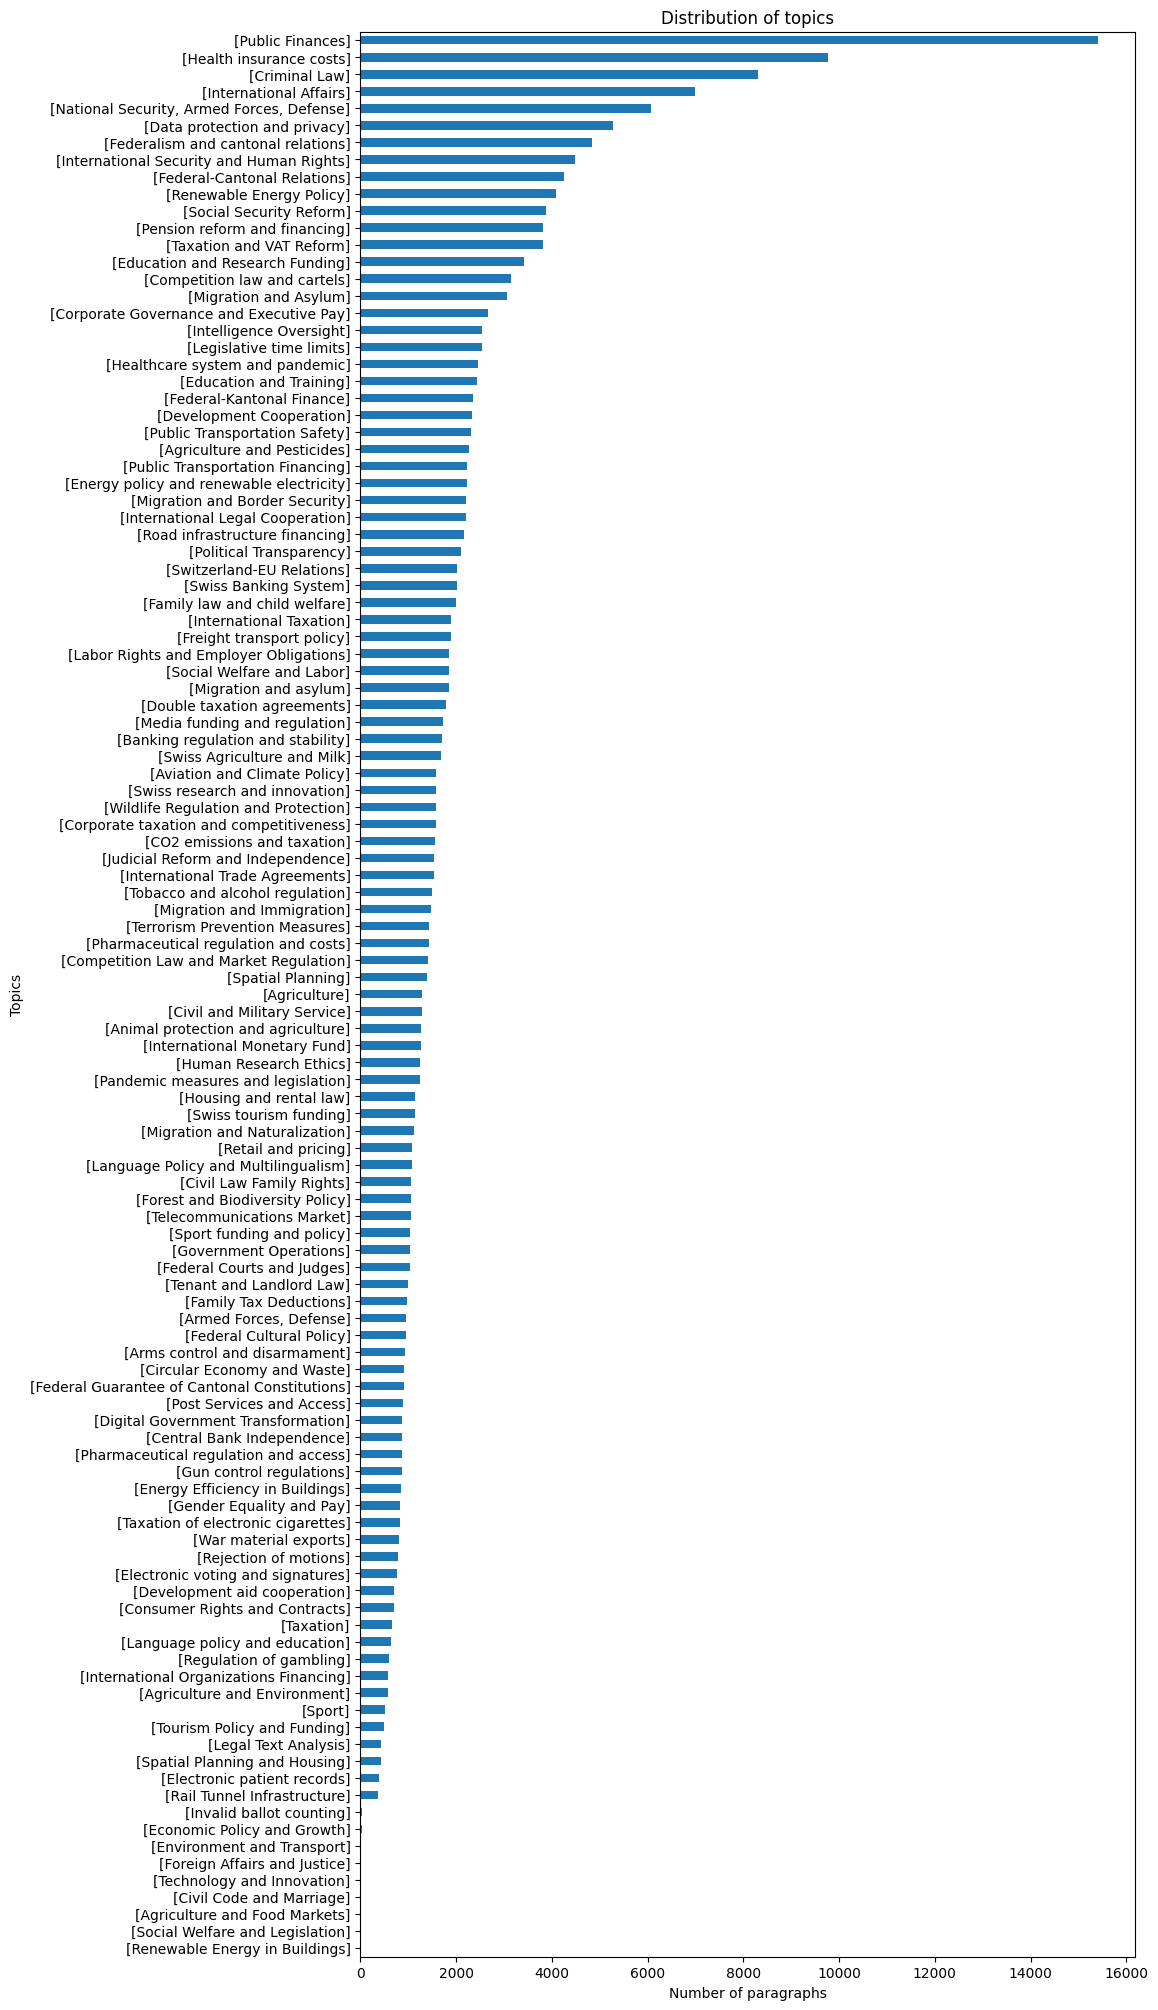

In [41]:
clean_doc_topics['Representation'].value_counts(ascending=True).plot(kind="barh", title="Distribution of topics", figsize=(10, 25), xlabel="Number of paragraphs", ylabel="Topics")

In [42]:
import gc
gc.collect()

272

In [43]:
full_df = pd.concat([df, clean_doc_topics], axis=1, join="inner")
full_df = full_df.drop(columns=["Document"])
full_df.to_json("speeches_with_topics.json", orient="records", lines=True, force_ascii=False)